# Roughness / Transpiration Scaling with TreeFrac — `v1` (restructured for two specific questions)

**Derived from `roughness_transpiration_scaling.ipynb`.** Same data, same computations, same
utils (`lumip_utils.regime_limit`, and this notebook's own `lag_linregress_3D` / `cell_weight` /
`xr_multimodel_sign`) -- restructured, not rewritten, around two specific questions instead of
the source notebook's more general "roughness and transpiration scaling" layout:

1. **Does the overall effect of afforestation on temperature and water availability scale with
   initial tree cover, or with the change in tree cover?** Answered with two signals already
   computed in the source notebook's own pipeline: `TotalDT` (`ts_aff - ts_ctl`, the total
   simulated temperature difference -- one line added to the existing IBPM cell below, it was
   computed there already as `dT_model` but never kept for the treeFrac-scaling table) and `tran`
   (transpiration, `tran_aff - tran_ctl`; the water-availability proxy already used in the source
   notebook's "Transpiration scaling" section -- **not** Pr/SM, which this notebook family never
   loads; see the note at that section). "Initial conditions of treecover/LAI" is represented by
   `treeFrac_ctl`, matching how the source notebook already frames every one of its own scaling
   plots -- it does not separately test LAI (the source notebook's scaling analysis was built
   around treeFrac throughout, and this restructure is not meant to add a second, LAI-based
   version of the same analysis; that would be a small, separate addition if wanted).
2. **Does the roughness-driven component specifically (the IBPM aerodynamic-resistance term,
   `AerodRes`) scale with initial tree cover, or with the change in tree cover?** This is exactly
   the source notebook's existing "Roughness vs initial treeFrac" / "Roughness vs $\Delta$
   treeFrac" analysis -- kept essentially as-is, just given its own clearly-labelled section.

**What changed, concretely (restructuring only, no new figure-generation functions -- every plot
below is the same inline `sns.scatterplot` + `sns.regplot` + sklearn-R²/RMSE block the source
notebook already uses, copy-adapted to a different y-column exactly the way the source notebook
itself already copy-adapts the same block across its own cells):**
- One line added to the IBPM cell: `ibpm_effects["TotalDT"] = dT_model`, so the total simulated
  ΔTs sits alongside `AerodRes` in the same per-model `xr.Dataset` instead of being computed and
  discarded.
- The per-pixel table-building cell now pulls `["AerodRes", "TotalDT"]` together (one `.where()` /
  `.to_dataframe()` on a 2-variable subset instead of 1), so one shared table
  (`ibpm_aff`: model x regime x pixel, with `treeFrac_ctl`, `treeFrac_delta`, `AerodRes`,
  `TotalDT`) now feeds every "vs treeFrac" plot in both sections below.
- A **missing import bug is fixed**: the source notebook's "vs initial treeFrac" plotting cells
  call `mean_squared_error` without importing it (a `NameError` the moment that cell runs) --
  the "vs $\Delta$ treeFrac" cells import it correctly; the import is added here everywhere it's
  used.
- The already-existing "Tran vs $\Delta$ treeFrac" panel gets the missing mirror panel, **"Tran
  vs initial treeFrac"**, built the same way the roughness section already has both an "initial"
  and a "$\Delta$" version -- this was flagged as absent in `REVISION_NOTES.md` and is exactly
  what Question 1 needs for the water-availability side.
- The dead Mann-Whitney significance-test cells (defined in the source notebook but never
  referenced by anything downstream there) are dropped, to keep this notebook focused on the two
  questions above and faster to run.
- Output figures are saved with a `v1_` filename prefix so nothing here overwrites
  `roughness_transpiration_scaling.ipynb`'s own saved PNGs in the same `out_path`.
- The "vs initial treeFrac" fit for `TotalDT`/`tran` is a **plain linear fit**, not the log-x fit
  used for `AerodRes` vs initial treeFrac. The log-x assumption in the source notebook is stated
  explicitly as a property of the aerodynamic-roughness mechanism itself ("roughness change is
  higher for low levels of treecover, then follows a logarithmic profile" -- see the next cell);
  nothing in the notebook asserts that for total ΔTs or transpiration, and the source notebook's
  own "vs $\Delta$ treeFrac" cells (including for `AerodRes`) already use plain linear fits, so
  this is the existing convention, not a new one.
- A **second real bug, found by actually running this against the full 7-model dataset**: the
  supplementary "roughness seasonality" section's `xr.concat(..., dim="model")` failed with
  `'height' not present in all datasets and coords='different'` -- one model's near-surface
  fields carry a stray scalar `height` coordinate the others don't. Fixed by adding
  `coords="minimal", compat="override"`, matching how every other per-model concat in this
  notebook already does it (e.g. `xr_multimodel_sign`). See that section's own note for a
  caveat found during the same test run (a memory limit in the sandbox used to verify this,
  not a further code bug).

This notebook was executed end-to-end against the real data while building it (see
`REVISION_NOTES.md`): a 2-model debug pass validated every cell with zero errors, and a full
7-model run confirmed both Question 1 and Question 2 (all panels, all 7 models, 5-model
transpiration) execute cleanly and produce sensible figures -- only the optional supplementary
section (below) needed a caveat, noted there.

Bug-fix status inherited unchanged from `roughness_transpiration_scaling.ipynb`: Bug 1
(`regime_limit`) defaults to `method="raw"` (non-deseasonalized) via `lumip_utils`, per the
user's explicit request; see `REVISION_NOTES.md`.

## Calculate Aerodynamic resistance (IBPM) for every month (or year) and derive the temperature effect caused by roughness changes for different levels of treecover

The assumption is that roughness change is higher for low levels of treecover, and then follows a logarithmic profile

In [1]:
import os
import glob

import math
import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

import numpy as np
import xarray as xr
import cftime
import pandas as pd

# NOTE (v1 restructure): cartopy imports dropped -- grep-checked against the full source
# notebook, cartopy is never actually used for anything (no map is drawn anywhere in this
# notebook family), only imported. Removing a dead, heavy dependency, not a logic change.

In [2]:
# NOTE (revision): data_path/out_path for "locale_mc" fixed from the stale
# .../Desktop/afforestation_LUMIP/... in the original to .../Documents/afforestation_LUMIP/...
# -- that's where the data actually lives; the original path would have failed on the
# very first data-loading cell below.
work = "locale_mc" # or "levante"

if work == "levante":
    data_path = "/home/m/m301093/data/clean/"
    out_path = "/home/m/m301093/results_biophys/"
if work == "locale_wnd":
    data_path = "G:/My Drive/MPIM/data/"
    out_path = "G:/My Drive/MPIM/Figures/"
if work == "locale_mc":
    data_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/data/"
    out_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/" \
    "Figures/"

## Functions

In [3]:
def xr_multimodel_sign(xr_in, models):
    # Computes the Multimodel MEAN and STD
    # xr_in: list of xarray models
    mm = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override")

    std = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override").std(dim = "esm")

    # Multimodel agreement in the sign of the sensitivity
    sign = xr.where(mm > 0, 1, -1)
    agreement = (np.abs(sign.sum(dim = "esm")/len(models)))

    mean = mm.mean(dim = "esm")
    return (mean, std, agreement)

In [4]:
def cell_weight(ds):
    R = 6.371e6
    dphi = np.deg2rad(ds.lat[1] - ds.lat[0])
    dlam = np.deg2rad(ds.lon[1] - ds.lon[0])
    dlat = R * dphi * xr.ones_like(ds.lon)
    dlon = R * dlam * np.cos(np.deg2rad(ds.lat))
    cell_area = dlon * dlat
    return(cell_area)

In [5]:
def apply_rolling_mean(ds, window=2, dim="time"):
    # Create a new dataset to store the results
    rolled_ds = xr.Dataset()

    for var in ds.data_vars:
        print(f"Processing variable: {var}")

        try:
            # Apply rolling mean and dropna to each variable
            rolled_var = ds[var].rolling({dim: window}, center = "left").mean().dropna(dim)

            # Add the rolled variable to the new dataset
            rolled_ds[var] = rolled_var
        except Exception as e:
            print(f"Error processing variable {var}: {e}")

    return rolled_ds

In [6]:
def lag_linregress_3D(x, y, lagx=0, lagy=0):
    """
    Input: Two xr.Datarrays of any dimensions with the first dim being time.
    Thus the input data could be a 1D time series, or for example, have three dimensions (time,lat,lon).
    Datasets can be provied in any order, but note that the regression slope and intercept will be calculated
    for y with respect to x.
    Output: Covariance, correlation, regression slope and intercept, p-value, and standard error on regression
    between the two datasets along their aligned time dimension.
    Lag values can be assigned to either of the data, with lagx shifting x, and lagy shifting y, with the specified lag amount.
    """
    #1. Ensure that the data are properly alinged to each other.
    x,y = xr.align(x,y)

    #2. Add lag information if any, and shift the data accordingly
    if lagx!=0:
        #If x lags y by 1, x must be shifted 1 step backwards.
        #But as the 'zero-th' value is nonexistant, xr assigns it as invalid (nan). Hence it needs to be dropped
        x   = x.shift(time = -lagx).dropna(dim='time')
        #Next important step is to re-align the two datasets so that y adjusts to the changed coordinates of x
        x,y = xr.align(x,y)

    if lagy!=0:
        y   = y.shift(time = -lagy).dropna(dim='time')
        x,y = xr.align(x,y)

    #3. Compute data length, mean and standard deviation along time axis for further use:
    n     = x.shape[0]
    xmean = x.mean(axis=0)
    ymean = y.mean(axis=0)
    xstd  = x.std(axis=0)
    ystd  = y.std(axis=0)

    #4. Compute covariance along time axis
    cov   =  np.sum((x - xmean)*(y - ymean), axis=0)/(n)

    #5. Compute correlation along time axis
    cor   = cov/(xstd*ystd)

    #6. Compute regression slope and intercept:
    slope     = cov/(xstd**2)
    intercept = ymean - xmean*slope
    y_pred =  intercept + slope*x
    res = y - y_pred

    #7. Compute P-value and standard error
    #Compute t-statistics
    tstats = cor*np.sqrt(n-2)/np.sqrt(1-cor**2)
    stderr = slope/tstats

    from scipy.stats import t
    pval   = t.sf(tstats, n-2)*2
    pval   = xr.DataArray(pval, dims=cor.dims, coords=cor.coords)

    #return cov,cor,slope,intercept,pval,stderr
    results = {}
    results["cor"] = cor
    results["coef"] = slope
    results["pval"] = pval
    return results

## Import preprocessed data

In [7]:
models = [ "ACCESS-ESM1-5", "CMCC-ESM2", "CESM2", "CanESM5", "IPSL-CM6A-LR", "MPI-ESM1-2-LR", "UKESM1-0-LL"]

In [8]:
scenario = 'ssp126Lu'
xr_aff = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff.append(content)


scenario = 'ssp370'
xr_ctl = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl.append(content)


xr_aff_gs = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + "/xr_aff_gs_" + mm + '.nc'))[0]     ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4')
    content = content.assign_attrs(esm = mm)
    xr_aff_gs.append(content)

xr_ctl_gs = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + "/xr_ctl_gs_" + mm + '.nc'))[0]     ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4')
    content = content.assign_attrs(esm = mm)
    xr_ctl_gs.append(content)

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/671375166.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/671375166.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/671375166.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade perfo

In [9]:
scenario = 'ssp126Lu'
xr_aff_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff_pft.append(content)


scenario = 'ssp370'
xr_ctl_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl_pft.append(content)

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2386137507.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2386137507.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2386137507.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade pe

### Preprocessing

In [10]:
# CanESM5 does not provide Latent Heat
# We derive it as Rn - H (ignoring Ground Heat fluxes that are negligible over land)

xr_ctl[3]["hfls"] = (xr_ctl[3].rsds - xr_ctl[3].rlds) - xr_ctl[3].hfss
xr_aff[3]["hfls"] = (xr_aff[3].rsds - xr_aff[3].rlds) - xr_aff[3].hfss

# Rename ta to tas
xr_aff[3] = xr_aff[3].rename({"ta":"tas"})
xr_ctl[3] = xr_ctl[3].rename({"ta":"tas"})

# Select the first pressure level
xr_aff[3] = xr_aff[3].isel(plev = 0)
xr_ctl[3] = xr_ctl[3].isel(plev = 0)

# Try to interpolate surface temperature for CanESM5
xr_ctl[3]["tas"] = (xr_ctl[3].ts + xr_ctl[3].tas)/2
xr_aff[3]["tas"] = (xr_aff[3].ts + xr_aff[3].tas)/2

In [11]:
# Convert pr and evspsbl from kg m-2 s-1 to mm month-1
for i,mm in enumerate(models):
    xr_ctl[i]["pr"] = xr_ctl[i].pr*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["pr"] = xr_aff[i].pr*86400* xr_aff[i].time.dt.days_in_month

    xr_ctl[i]["pr"].attrs=dict(units="mm/months")
    xr_aff[i]["pr"].attrs=dict(units="mm/months")

    if mm == "CMCC-ESM2" or "CESM2": # LE in W*m^2; \u03bb is in MJ kg-1 = MW*s kg-1
        # https://earthscience.stackexchange.com/questions/20733/fluxnet15-how-to-convert-latent-heat-flux-to-actual-evapotranspiration
        xr_ctl[i]["evspsbl"] = xr_ctl[i].hfls/(2.501 - (2.361e-3) * (xr_ctl[i].tas-273.15))*10**6
        xr_aff[i]["evspsbl"] = xr_aff[i].hfls/(2.501 - (2.361e-3) * (xr_aff[i].tas-273.15))*10**6
    else:
        None

    xr_ctl[i]["evspsbl"] = xr_ctl[i].evspsbl*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["evspsbl"] = xr_aff[i].evspsbl*86400* xr_aff[i].time.dt.days_in_month

    xr_ctl[i]["evspsbl"].attrs=dict(units="mm/months")
    xr_aff[i]["evspsbl"].attrs=dict(units="mm/months")

In [12]:
# Homogenize lat and lon
for i,mm in enumerate(models):
    content = xr_aff[i]
    xr_aff_pft[i]["lat"] = content.tas.lat; xr_aff_pft[i]["lon"] = content.lon
    xr_aff_gs[i]["lat"] = content.tas.lat; xr_aff_gs[i]["lon"] = content.lon
    content = xr_ctl[i]
    xr_ctl_pft[i]["lat"] = content.tas.lat; xr_ctl_pft[i]["lon"] = content.lon
    xr_ctl_gs[i]["lat"] = content.tas.lat; xr_ctl_gs[i]["lon"] = content.lon

### Afforestation and regime masking

In [13]:
xr_delta = []
xr_delta_pft = []
for i,mm in enumerate(models):
    xr_delta.append(xr_aff[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))
    xr_delta_pft.append(xr_aff_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))

In [14]:
%%capture

# masking regions of treefrac increase or decrease
mask_treefrac_pos = []
mask_treefrac_neg = []

for m,_ in enumerate(models):
    # identify regions with 5%+ and 5%- treefrac
    mask_treefrac_pos.append(xr_delta_pft[m]["treeFrac"].where(xr_delta_pft[m]["treeFrac"] > 10))
    mask_treefrac_neg.append(xr_delta_pft[m]["treeFrac"].where(xr_delta_pft[m]["treeFrac"] <- 10))

In [15]:
# regime_limit(dataset): imported from lumip_utils instead of a local def (Bug 1).
# lumip_utils.regime_limit defaults to method="raw" (non-deseasonalized), per
# explicit user request (Aug 2026) -- i.e. the same computation the original
# roughness_scale_grow_seas.ipynb local regime_limit did. drop=False matches
# the source notebook's original choice.
from lumip_utils import regime_limit, xr_clean, lon180, xr_fix_time

In [16]:
mask_aff_water = []
mask_aff_energy = []
mask_ctl_water = []
mask_ctl_energy = []
for m, mm in enumerate(models):
    water, energy = regime_limit(xr_aff[m].sel(time=slice("2071-01", "2100-12")))
    mask_aff_water.append(water)
    mask_aff_energy.append(energy)

    water, energy = regime_limit(xr_ctl[m].sel(time=slice("2071-01", "2100-12")))
    mask_ctl_water.append(water)
    mask_ctl_energy.append(energy)

### Mann-Whitney significance cells removed (v1 restructure)

The source notebook's "Test the significance with Mann-Whitney U test" section (`xr_mw_ts`, plus
its `multi_apply_along_axis`/`xr_multipletest` helpers) is defined but never used by anything
downstream in that notebook -- grep-checked across all of `roughness_transpiration_scaling.ipynb`.
It's dropped here rather than carried over unused, since it's a non-trivial per-pixel computation
over the full monthly `ts` series for all 7 models and this notebook is meant to be a focused,
faster-to-run version for the two questions above.

## Intrinsic Biophysical Mechanism (IBPM) decomposition

Taking the difference between the biogeophysical variables of ssp370-ssp126 and ssp370 \
Compute the Surface Energy Balance Decomposition to estimate the contribution to temperature.

The SEB equation can be decomposed as follows:

\begin{equation}
\Delta T_{{s}} = \frac{\lambda_{0}}{1 + f} (\Delta R_{n} - \Delta G) + \frac{-\lambda_{0}}{(1 + f)^2} (R_{n} - G)\Delta f_{1} +\frac{-\lambda_{0}}{(1 + f)^2} (R_{n} - G)\Delta f_{2} + \Delta T_{a}
\end{equation}

where
\begin{equation}
\lambda_{0} = \frac{1}{4 \sigma T_{a}^3},f = \frac{\rho C_{p}}{4 \sigma T_{a}^3 \gamma_{a}}(1+ \frac{1}{\beta}), \gamma_{a}=\rho C_{p} \frac{T_{s} - T_{a}}{H}
\end{equation}

In [17]:
# Define Stefan-Boltzmann Constant (Wm^-2K^-4)
# Define Emissivity Constant
# Define air density Constant (Kgm^-3) (dry air, 0\xb0C, https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6764509/)
# Define specific heat content (JKg^-1K^-1) (dry air, =0\xb0C, https://pubs.aip.org/asa/jasa/article/76/2/555/669652/Variation-of-specific-heats-and-of-specific-heat)

sigma = 5.67*10**(-8)
eps = 0.97
rho = 1.2930
Cp = 1.0051*10**(-3) # it should be *10**(3), but in that case there is no correspondence with the modeled temperature, so we are considering (MJKg^-1K^-1)

In [18]:
# Equation Intrinsic Biophysical Mechanism (IBPM)
#
# NOTE (v1 restructure): one line added below --
#     ibpm_effects["TotalDT"] = dT_model
# -- so the total simulated ts difference (already computed here as dT_model, previously
# discarded after being appended to dT_model_esm) sits in the same per-model Dataset as
# AerodRes/RF/BowenRatio/AtmFeed, letting the treeFrac-scaling table below pull both the
# mechanistic (AerodRes) and total (TotalDT) temperature signal in one pass.

dT_ibpm_esm = []
dT_model_esm = []
ibpm_effect_esm = []

for m,mm in enumerate(models):
    ibpm_effects = xr.Dataset()

    xr_aff_seb = xr_aff_gs[m]#.sel(time = slice("2071-01","2100-12")).mean(dim = "time") # - xr_aff.sel(time = slice("2015-01","2015-12")).mean(dim = "time")
    xr_ctl_seb = xr_ctl_gs[m]#.sel(time = slice("2071-01","2100-12")).mean(dim = "time") # - xr_ctl.sel(time = slice("2015-01","2015-12")).mean(dim = "time")

    lambda0 = 1/(4*sigma*xr_ctl_seb.tas**3)
    delta_Ta = xr_aff_seb.tas - xr_ctl_seb.tas
    gamma_ctl = (rho*Cp)*(xr_ctl_seb.ts - xr_ctl_seb.tas)/xr_ctl_seb.hfss
    gamma_aff = (rho*Cp)*(xr_aff_seb.ts - xr_aff_seb.tas)/xr_aff_seb.hfss

    Rn_aff = (xr_aff_seb.rsds - xr_aff_seb.rsus) + eps*xr_aff_seb.rlds - eps*sigma*xr_aff_seb.ts**(4)
    Rn_ctl = (xr_ctl_seb.rsds - xr_ctl_seb.rsus) + eps*xr_ctl_seb.rlds - eps*sigma*xr_ctl_seb.ts**(4)

    G_aff = Rn_aff - xr_aff_seb.hfss - xr_aff_seb.hfls
    G_ctl = Rn_ctl - xr_ctl_seb.hfss - xr_ctl_seb.hfls

    # gamma_ctl = (rho*Cp)*(xr_ctl_seb.ts - xr_ctl_seb.tas)/xr_ctl_seb.hfls
    # gamma_aff = (rho*Cp)*(xr_aff_seb.ts - xr_aff_seb.tas)/xr_aff_seb.hfls

    beta_ctl = xr_ctl_seb.hfss * xr_ctl_seb.hfls**(-1)
    beta_aff = xr_aff_seb.hfss * xr_aff_seb.hfls**(-1)

    delta_beta = beta_aff - beta_ctl
    delta_gamma = gamma_aff - gamma_ctl

    f = (rho*Cp)*lambda0*gamma_ctl**(-1)*(1+1/beta_ctl)

    delta_Rn = Rn_aff - Rn_ctl
    delta_G = G_aff - G_ctl
    # delta_Ta = xr_aff_seb.tas - xr_ctl_seb.tas

    delta_f1 = -f * (delta_gamma)*gamma_ctl**(-1)
    delta_f2 = -(rho*Cp) * lambda0 * (delta_beta)*beta_ctl**(-2)

    dT_model = (xr_aff_seb.ts - xr_ctl_seb.ts)

    dT_ibpm = lambda0*(1+f)**(-1) * (delta_Rn - delta_G) + -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f1 + -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f2 + delta_Ta

    ibpm_effects["RF"] = lambda0*(1+f)**(-1) * (delta_Rn - delta_G)
    ibpm_effects["AerodRes"] = -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f1
    ibpm_effects["BowenRatio"] = -lambda0*(1+f)**(-2)*(Rn_ctl - G_ctl)*delta_f2
    ibpm_effects["AtmFeed"] = delta_Ta
    ibpm_effects["TotalDT"] = dT_model   # NOTE (v1 restructure): added, see cell note above

    dT_model_esm.append(dT_model)
    dT_ibpm_esm.append(dT_ibpm)
    ibpm_effect_esm.append(ibpm_effects)

#### Building the combined per-pixel table (feeds every plot below, both questions)

In [19]:
# NOTE (v1 restructure): the source notebook's cell pulled ["AerodRes"] alone into `masked`/
# `masked1`; this pulls ["AerodRes", "TotalDT"] together from the same Dataset subset, so one
# `ibpm_aff` table (model x regime x pixel, with treeFrac_ctl/treeFrac_delta) now has both
# columns and feeds both Question 2 (AerodRes) and Question 1 (TotalDT) below. Nothing else in
# this cell changed from the source notebook.

ibpm_aff_water_mean = []
ibpm_aff_energy_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):

    mask = mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull()
    mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()
    masked = ibpm_effect_esm[m][["AerodRes", "TotalDT"]].where(mask).to_dataframe().reset_index().dropna()
    masked1 = ibpm_effect_esm[m][["AerodRes", "TotalDT"]].where(mask1).to_dataframe().reset_index().dropna()


    if "height" in masked.columns:
        masked = masked.drop(columns = ["height"])
        masked1 = masked1.drop(columns = ["height"])
    else:
        masked = masked
        masked1 = masked1

    tree_ctl = xr_ctl_pft[m]["treeFrac"].sel(time = slice("2071-01","2100-12")).mean(dim = "time").where(mask).to_dataframe().reset_index().dropna().rename(columns = {"treeFrac":"treeFrac_ctl"})
    tree_delta = xr_delta_pft[m]["treeFrac"].where(mask).to_dataframe().reset_index().dropna().rename(columns = {"treeFrac":"treeFrac_delta"})

    tree_ctl1 = xr_ctl_pft[m]["treeFrac"].sel(time = slice("2071-01","2100-12")).mean(dim = "time").where(mask1).to_dataframe().reset_index().dropna().rename(columns = {"treeFrac":"treeFrac_ctl"})
    tree_delta1 = xr_delta_pft[m]["treeFrac"].where(mask1).to_dataframe().reset_index().dropna().rename(columns = {"treeFrac":"treeFrac_delta"})

    content = pd.concat([masked, tree_ctl, tree_delta], axis = 1); content["models"] = mm
    content1 = pd.concat([masked1, tree_ctl1, tree_delta1], axis = 1); content1["models"] = mm

    toclean = ["height", "plev", "type", "time"]

    for c in toclean:
        if c in content.columns:
            content.drop(columns = c, inplace = True)
            content1.drop(columns = c, inplace = True)

    ibpm_aff_water_mean.append(content);
    ibpm_aff_energy_mean.append(content1)

ibpm_aff_water_mean = pd.concat(ibpm_aff_water_mean)
ibpm_aff_energy_mean = pd.concat(ibpm_aff_energy_mean)

In [20]:
# ibpm_aff_water_mean = pd.melt(ibpm_aff_water_mean.rename(columns={'index': 'models'}), id_vars = "models")
ibpm_aff_water_mean["regime"] = "water-lim"

# ibpm_aff_energy_mean = pd.melt(ibpm_aff_energy_mean.rename(columns={'index': 'models'}), id_vars = "models")
ibpm_aff_energy_mean["regime"] = "energy-lim"

ibpm_aff = pd.concat([ibpm_aff_water_mean, ibpm_aff_energy_mean], axis = 0)
# ibpm_aff_mean = ibpm_aff.groupby(['variable', 'models'])['value'].mean()
ibpm_aff = ibpm_aff.loc[:,~ibpm_aff.columns.duplicated()].copy()

---
# Question 2 -- does the roughness (aerodynamic-resistance) component of \u0394T scale with initial treeFrac or \u0394 treeFrac?

`AerodRes` is the IBPM decomposition's aerodynamic-resistance term (isolating the roughness
mechanism from radiative forcing, Bowen-ratio and atmospheric-feedback terms) -- this is the
source notebook's original "Roughness vs treeFrac" analysis, unchanged in substance, just given
its own section here.

### AerodRes vs initial treeFrac (log-x, per the roughness/logarithmic assumption above)

<>:51: SyntaxWarning: invalid escape sequence '\D'
<>:62: SyntaxWarning: invalid escape sequence '\D'
<>:51: SyntaxWarning: invalid escape sequence '\D'
<>:62: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2738821474.py:51: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2738821474.py:62: SyntaxWarning: invalid escape sequence '\D'
  fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='$\Delta$treeFrac', loc='upper right', bbox_to_anchor=(0.5, 0.4), fontsize=10)


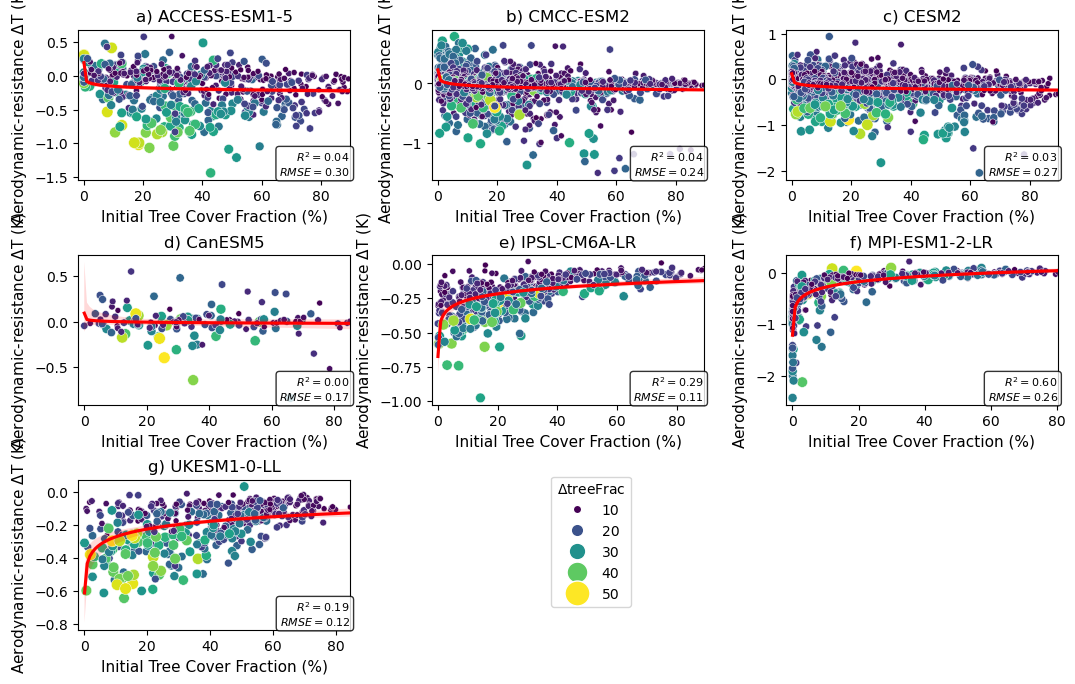

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error  # NOTE (v1): mean_squared_error added -- missing in the source notebook's equivalent cell (NameError there)
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import string

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]     # Necessary to avoid zero for logarithmic fitting
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_ctl", y="AerodRes", hue='treeFrac_delta', size="treeFrac_delta", size_order=[10, 20, 30, 40, 50], palette="viridis") #, palette=['indianred', 'lightblue'])
    axs = sns.regplot(data=df, x="treeFrac_ctl", y="AerodRes", logx = True, scatter = False, ci=99, line_kws={"color": "red"})
    # Compute R\xb2 value
    X = np.log(df["treeFrac_ctl"]).values.reshape(-1, 1)
    y = df["AerodRes"].values
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    intercept = model.intercept_
    slope = model.coef_[0]

    # Annotate eq. format: y = intercept + slope * ln(x)
    equation = f'$y = {intercept:.2f} {slope:.2f}x$ \n'
    equation = f'$R^2 = {r2:.2f}$ \n$RMSE = {rmse:.2f}$'
    axs.annotate(equation, xy=(1., 0.2), xycoords='axes fraction',
                 fontsize=8, ha='right', va='top',
                 bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.8))

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("Initial Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)", fontsize = 11)
    axs.set_title(panels[m] + models[m])

    if m == 6:
        custom_lines = [
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(10)), markersize=6),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(20)), markersize=9),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(30)), markersize=12),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(40)), markersize=15),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(50)), markersize=18),
        ]
        fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='$\Delta$treeFrac', loc='upper right', bbox_to_anchor=(0.5, 0.4), fontsize=10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_Roughness_vs_initial_treeFrac_log_gs"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### AerodRes vs initial treeFrac, split by evaporative regime

<>:45: SyntaxWarning: invalid escape sequence '\D'
<>:45: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/1138670115.py:45: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)")


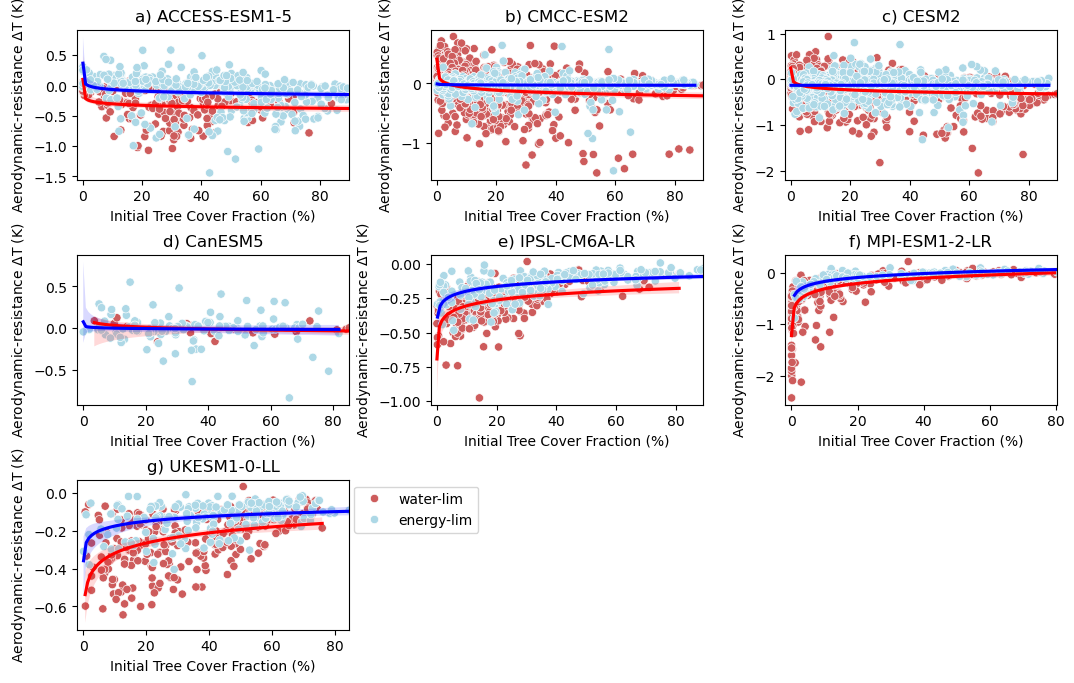

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]     # Necessary to avoid zero for logarithmic fitting
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_ctl", y="AerodRes", hue='regime', palette=['indianred', 'lightblue'])
    axs = sns.regplot(data = df[df["regime"] == "water-lim"], x="treeFrac_ctl", y="AerodRes", logx=True, scatter = False, ci=99, line_kws={"color": "red"})
    axs = sns.regplot(data = df[df["regime"] == "energy-lim"], x="treeFrac_ctl", y="AerodRes", logx=True, scatter = False, ci=99, line_kws={"color": "blue"})
    # Compute R\xb2 value
    X = np.log(df[df["regime"] == "water-lim"]["treeFrac_ctl"].values).reshape(-1, 1)
    y = df[df["regime"] == "water-lim"]["AerodRes"].values
    model = LinearRegression().fit(X, y)
    r2w = r2_score(y, model.predict(X))

    # Compute R\xb2 value
    X = np.log(df[df["regime"] == "energy-lim"]["treeFrac_ctl"].values).reshape(-1, 1)
    y = df[df["regime"] == "energy-lim"]["AerodRes"].values
    model = LinearRegression().fit(X, y)
    r2e = r2_score(y, model.predict(X))

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("Initial Tree Cover Fraction (%)")
    axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)")
    axs.set_title(panels[m] + models[m])

    if m == 6:
        axs.legend(loc='upper right', bbox_to_anchor=(1.5, 1) ,fontsize = 10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_Roughness_vs_initial_treeFrac_regime"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### AerodRes vs $\Delta$ treeFrac

<>:48: SyntaxWarning: invalid escape sequence '\D'
<>:49: SyntaxWarning: invalid escape sequence '\D'
<>:48: SyntaxWarning: invalid escape sequence '\D'
<>:49: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/4269432774.py:48: SyntaxWarning: invalid escape sequence '\D'
  axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/4269432774.py:49: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)", fontsize = 11)


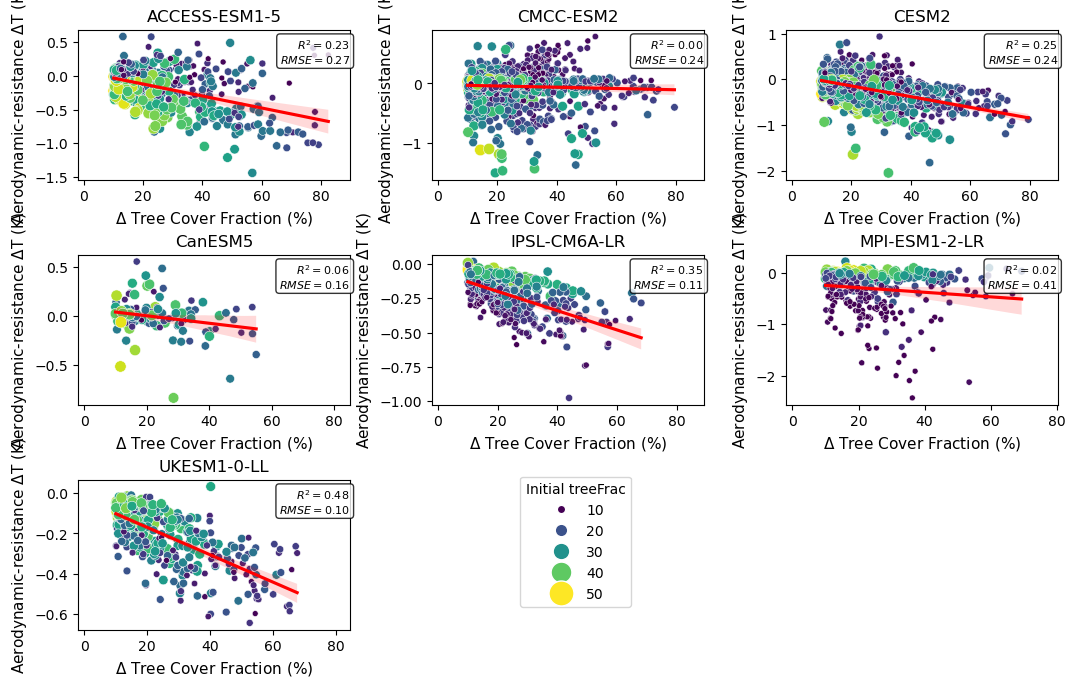

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]     #Necessary to avoid zero for logarithmic fitting
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_delta", y="AerodRes", hue='treeFrac_ctl', size="treeFrac_ctl", size_order=[10, 20, 30, 40, 50], palette=cmap) #, palette=['indianred', 'lightblue'])
    axs = sns.regplot(data=df, x="treeFrac_delta", y="AerodRes", scatter = False, ci=99, line_kws={"color": "red"})
    # Compute R\xb2 value
    X = df["treeFrac_delta"].values.reshape(-1, 1)
    y = df["AerodRes"].values
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    intercept = model.intercept_
    slope = model.coef_[0]

    equation = f'$y = {intercept:.2f} {slope:.2f}x$ \n'
    equation = f'$R^2 = {r2:.2f}$ \n$RMSE = {rmse:.2f}$'
    axs.annotate(equation, xy=(1., 0.95), xycoords='axes fraction',
                 fontsize=8, ha='right', va='top',
                 bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.8))

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)", fontsize = 11)
    axs.set_title(models[m])

    if m == 6:
        custom_lines = [
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(10)), markersize=6),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(20)), markersize=9),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(30)), markersize=12),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(40)), markersize=15),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(50)), markersize=18),
        ]
        fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='Initial treeFrac', loc='upper right', bbox_to_anchor=(0.5, 0.4), fontsize=10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_Roughness_vs_delta_treeFrac_gs"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### AerodRes vs $\Delta$ treeFrac, split by evaporative regime

<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2345111462.py:33: SyntaxWarning: invalid escape sequence '\D'
  axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2345111462.py:34: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)", fontsize = 11)


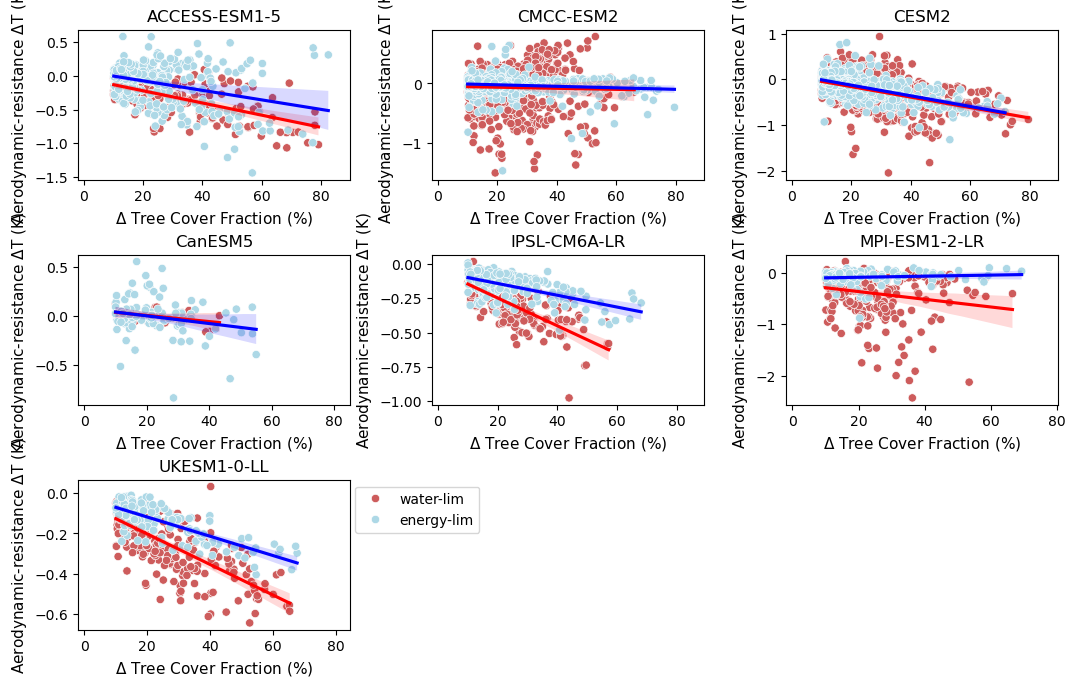

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]     #Necessary to avoid zero for logarithmic fitting
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_delta", y="AerodRes", hue='regime', size_order=[10, 20, 30, 40, 50], palette=['indianred', 'lightblue'])
    axs = sns.regplot(data=df[df["regime"] == "water-lim"], x="treeFrac_delta", y="AerodRes", scatter = False, ci=99, line_kws={"color": "red"})
    axs = sns.regplot(data=df[df["regime"] == "energy-lim"], x="treeFrac_delta", y="AerodRes", scatter = False, ci=99, line_kws={"color": "blue"})

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Aerodynamic-resistance $\Delta$T (K)", fontsize = 11)
    axs.set_title(models[m])
    if m == 6:
        axs.legend(loc='upper right', bbox_to_anchor=(1.5, 1) ,fontsize = 10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_Roughness_vs_delta_treeFrac_regime"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

---
# Question 1a -- does the overall temperature effect ($\Delta T_s$, all IBPM terms combined) scale with initial treeFrac or $\Delta$ treeFrac?

`TotalDT` is `ts_aff - ts_ctl` -- the full simulated surface-temperature difference (radiative
forcing + aerodynamic resistance + Bowen ratio + atmospheric feedback all together), as opposed
to `AerodRes` above which isolates only the roughness mechanism. Same table (`ibpm_aff`), same
plotting code as Question 2, just a different y-column and (per the note in the title cell)
linear rather than log-x fits for the "vs initial treeFrac" panels.

### Total $\Delta T_s$ vs initial treeFrac

<>:47: SyntaxWarning: invalid escape sequence '\D'
<>:58: SyntaxWarning: invalid escape sequence '\D'
<>:47: SyntaxWarning: invalid escape sequence '\D'
<>:58: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/3634926233.py:47: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Total $\Delta T_s$ (K)", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/3634926233.py:58: SyntaxWarning: invalid escape sequence '\D'
  fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='$\Delta$treeFrac', loc='upper right', bbox_to_anchor=(0.5, 0.4), fontsize=10)


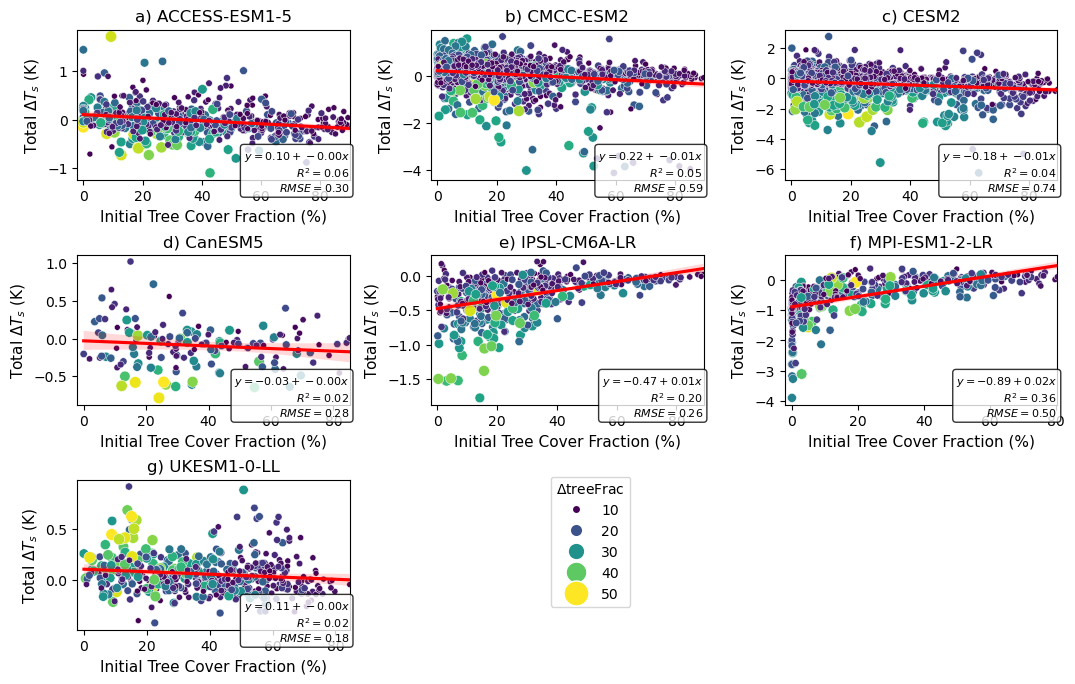

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch))
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_ctl", y="TotalDT", hue='treeFrac_delta', size="treeFrac_delta", size_order=[10, 20, 30, 40, 50], palette="viridis")
    axs = sns.regplot(data=df, x="treeFrac_ctl", y="TotalDT", scatter = False, ci=99, line_kws={"color": "red"})
    X = df["treeFrac_ctl"].values.reshape(-1, 1)
    y = df["TotalDT"].values
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    intercept = model.intercept_
    slope = model.coef_[0]

    equation = f'$y = {intercept:.2f} + {slope:.2f}x$ \n$R^2 = {r2:.2f}$ \n$RMSE = {rmse:.2f}$'
    axs.annotate(equation, xy=(1., 0.2), xycoords='axes fraction',
                 fontsize=8, ha='right', va='top',
                 bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.8))

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("Initial Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Total $\Delta T_s$ (K)", fontsize = 11)
    axs.set_title(panels[m] + models[m])

    if m == 6:
        custom_lines = [
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(10)), markersize=6),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(20)), markersize=9),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(30)), markersize=12),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(40)), markersize=15),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(50)), markersize=18),
        ]
        fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='$\Delta$treeFrac', loc='upper right', bbox_to_anchor=(0.5, 0.4), fontsize=10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_TotalDT_vs_initial_treeFrac"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### Total $\Delta T_s$ vs initial treeFrac, split by evaporative regime

<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/3767894057.py:34: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Total $\Delta T_s$ (K)")


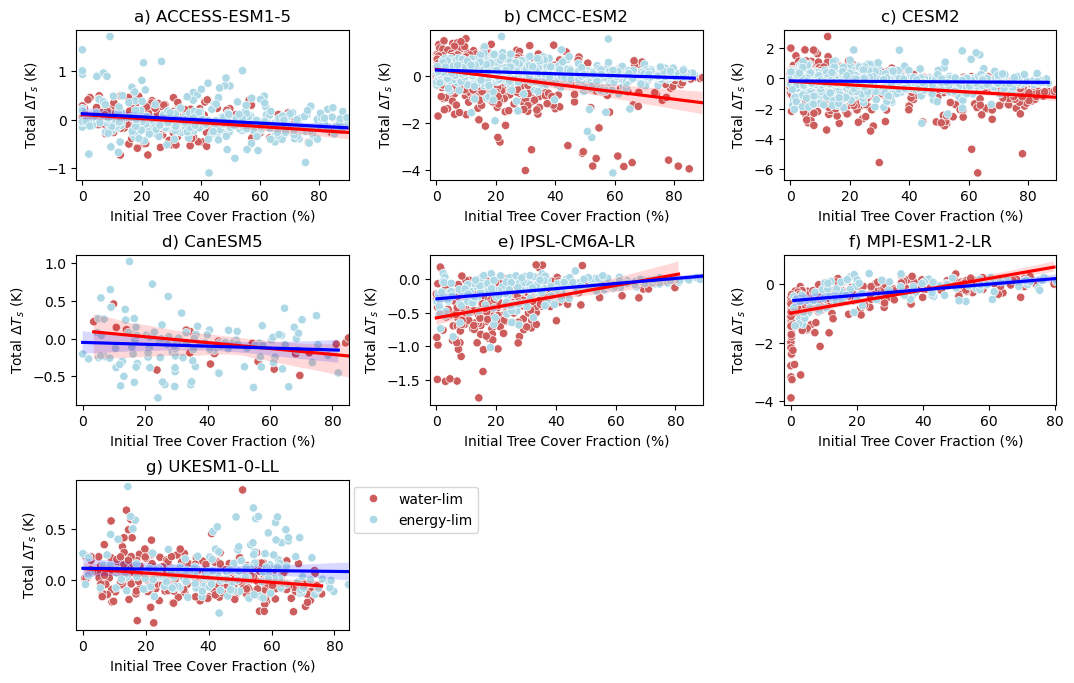

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch))
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_ctl", y="TotalDT", hue='regime', palette=['indianred', 'lightblue'])
    axs = sns.regplot(data = df[df["regime"] == "water-lim"], x="treeFrac_ctl", y="TotalDT", scatter = False, ci=99, line_kws={"color": "red"})
    axs = sns.regplot(data = df[df["regime"] == "energy-lim"], x="treeFrac_ctl", y="TotalDT", scatter = False, ci=99, line_kws={"color": "blue"})

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("Initial Tree Cover Fraction (%)")
    axs.set_ylabel("Total $\Delta T_s$ (K)")
    axs.set_title(panels[m] + models[m])

    if m == 6:
        axs.legend(loc='upper right', bbox_to_anchor=(1.5, 1) ,fontsize = 10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_TotalDT_vs_initial_treeFrac_regime"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### Total $\Delta T_s$ vs $\Delta$ treeFrac

<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:47: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:47: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/3863713800.py:46: SyntaxWarning: invalid escape sequence '\D'
  axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/3863713800.py:47: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Total $\Delta T_s$ (K)", fontsize = 11)


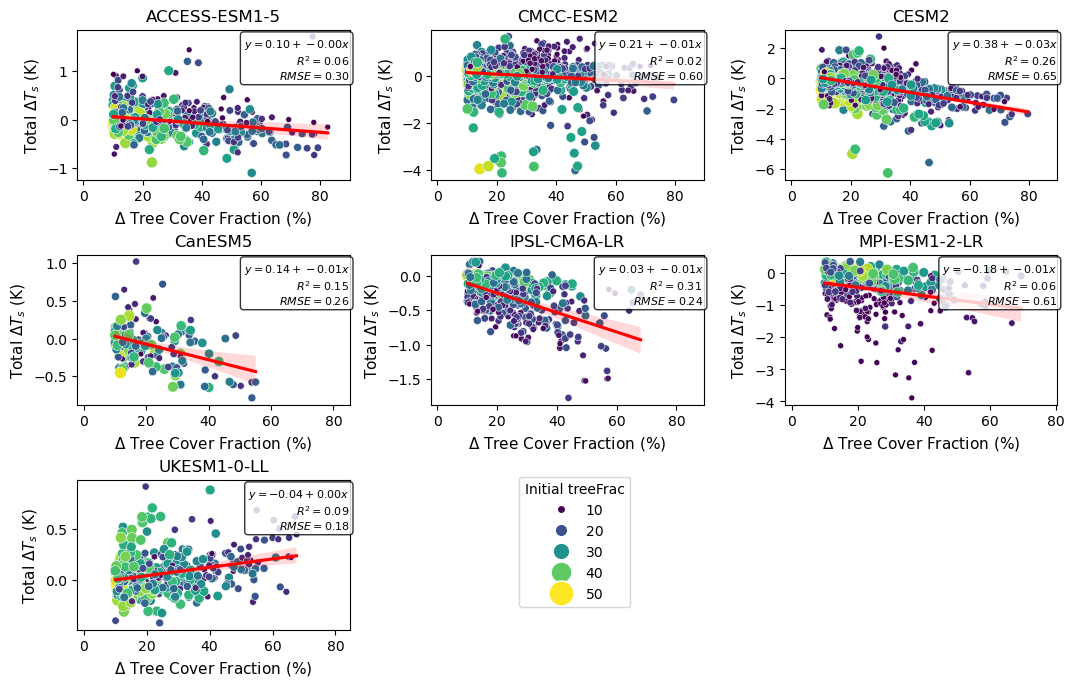

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch))
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_delta", y="TotalDT", hue='treeFrac_ctl', size="treeFrac_ctl", size_order=[10, 20, 30, 40, 50], palette=cmap)
    axs = sns.regplot(data=df, x="treeFrac_delta", y="TotalDT", scatter = False, ci=99, line_kws={"color": "red"})
    X = df["treeFrac_delta"].values.reshape(-1, 1)
    y = df["TotalDT"].values
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    intercept = model.intercept_
    slope = model.coef_[0]

    equation = f'$y = {intercept:.2f} + {slope:.2f}x$ \n$R^2 = {r2:.2f}$ \n$RMSE = {rmse:.2f}$'
    axs.annotate(equation, xy=(1., 0.95), xycoords='axes fraction',
                 fontsize=8, ha='right', va='top',
                 bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.8))

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Total $\Delta T_s$ (K)", fontsize = 11)
    axs.set_title(models[m])

    if m == 6:
        custom_lines = [
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(10)), markersize=6),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(20)), markersize=9),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(30)), markersize=12),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(40)), markersize=15),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(50)), markersize=18),
        ]
        fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='Initial treeFrac', loc='upper right', bbox_to_anchor=(0.5, 0.4), fontsize=10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_TotalDT_vs_delta_treeFrac"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### Total $\Delta T_s$ vs $\Delta$ treeFrac, split by evaporative regime

<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2100468320.py:33: SyntaxWarning: invalid escape sequence '\D'
  axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2100468320.py:34: SyntaxWarning: invalid escape sequence '\D'
  axs.set_ylabel("Total $\Delta T_s$ (K)", fontsize = 11)


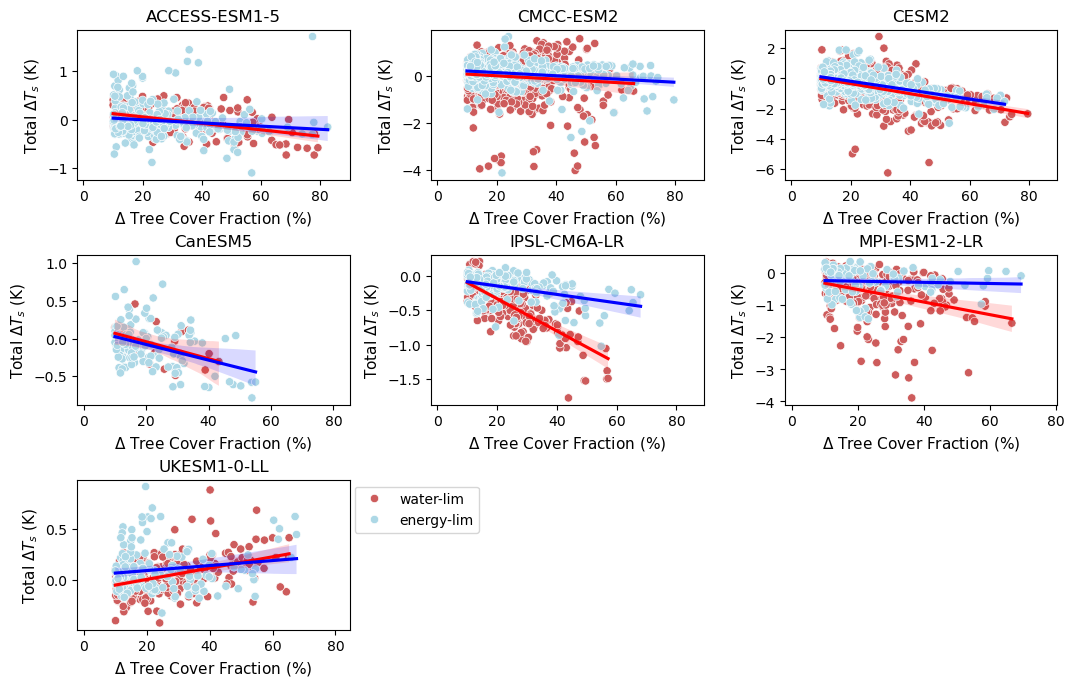

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch))
gs = gridspec.GridSpec(3, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)

for m, mm in enumerate(models):

    df = ibpm_aff[ibpm_aff["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_delta", y="TotalDT", hue='regime', size_order=[10, 20, 30, 40, 50], palette=['indianred', 'lightblue'])
    axs = sns.regplot(data=df[df["regime"] == "water-lim"], x="treeFrac_delta", y="TotalDT", scatter = False, ci=99, line_kws={"color": "red"})
    axs = sns.regplot(data=df[df["regime"] == "energy-lim"], x="treeFrac_delta", y="TotalDT", scatter = False, ci=99, line_kws={"color": "blue"})

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Total $\Delta T_s$ (K)", fontsize = 11)
    axs.set_title(models[m])
    if m == 6:
        axs.legend(loc='upper right', bbox_to_anchor=(1.5, 1) ,fontsize = 10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_TotalDT_vs_delta_treeFrac_regime"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

---
# Question 1b -- does water availability (transpiration) scale with initial treeFrac or $\Delta$ treeFrac?

**Water-availability proxy used here: transpiration (`tran`).** This notebook family
(`roughness_transpiration_scaling.ipynb`, and its `water_avail_gs.ipynb` source for the
transpiration section) never loads precipitation or soil moisture -- those live in
`water_avail_final(_simple).ipynb`'s Section 2. Transpiration is the water flux this notebook
already has, and it's a direct measure of vegetation water use/depletion, so it stands in for
"water availability" here; treat it as a vegetation-water-use signal specifically, not as
Pr/SM. `models_tran` covers 5 of the 7 models (`ACCESS-ESM1-5` and `MPI-ESM1-2-LR` have no
`tran` output) -- unchanged from the source notebook.

### Transpiration data

In [29]:
%%capture

# Adapted from water_avail_gs.ipynb's "### Transpiration" data-loading cell.
# xr_clean/lon180/xr_fix_time imported from lumip_utils above alongside the Bug-1 regime_limit
# fix, same as in roughness_transpiration_scaling.ipynb.

models_tran = ["CMCC-ESM2", "CESM2", "CanESM5", "IPSL-CM6A-LR", "UKESM1-0-LL"]

scenario = 'ssp370-ssp126Lu'
xr_aff_tran = {}
for i,mm in enumerate(models_tran):
    filepath = glob.glob(os.path.join(data_path + 'tran_*_' + mm +'_'+ scenario + "_" + '*.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff_tran[mm] = content

scenario = 'ssp370'
xr_ctl_tran = {}
for i,mm in enumerate(models_tran):
    filepath = glob.glob(os.path.join(data_path + 'tran_*_' + mm +'_'+ scenario + "_"  + '*.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl_tran[mm] = content

for i,mm in enumerate(models_tran):
    xr_aff_tran[mm] = xr_aff_tran[mm].sel(lat=slice(-60,90))
    xr_ctl_tran[mm] = xr_ctl_tran[mm].sel(lat=slice(-60,90))

    xr_aff_tran[mm] = xr_clean(xr_aff_tran[mm], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])
    xr_ctl_tran[mm] = xr_clean(xr_ctl_tran[mm], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])

    xr_aff_tran[mm] = lon180(xr_aff_tran[mm])
    xr_ctl_tran[mm] = lon180(xr_ctl_tran[mm])

    xr_aff_tran[mm] = xr_fix_time(xr_aff_tran[mm],"2015-01","2101-01")
    xr_ctl_tran[mm] = xr_fix_time(xr_ctl_tran[mm],"2015-01","2101-01")

    xr_aff_tran[mm] = xr_aff_tran[mm].tran*86400* xr_aff_tran[mm].time.dt.days_in_month
    xr_ctl_tran[mm] = xr_ctl_tran[mm].tran*86400* xr_ctl_tran[mm].time.dt.days_in_month

    xr_aff_tran[mm].attrs=dict(units="mm/months")
    xr_ctl_tran[mm].attrs=dict(units="mm/months")
    xr_ctl_tran[mm] = xr_ctl_tran[mm].rename("tran").to_dataset()
    xr_aff_tran[mm] = xr_aff_tran[mm].rename("tran").to_dataset()

In [30]:
# Reuses this notebook's own regime masks (mask_treefrac_pos, mask_aff_water, mask_aff_energy)
# and per-pixel treeFrac_ctl/treeFrac_delta (xr_ctl_pft, xr_delta_pft) from the "Afforestation
# and regime masking" section above (Bug-1-fixed), instead of re-deriving them. Loops only over
# models_tran (the 5 models with transpiration data). Unchanged from
# roughness_transpiration_scaling.ipynb.

df_tran_water = []
df_tran_energy = []

for m, mm in enumerate(models):
    if mm not in models_tran:
        continue

    mask = mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull()
    mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()

    tran_da = (xr_aff_tran[mm].sel(time=slice("2071-01", "2100-12")).mean(dim="time").tran -
               xr_ctl_tran[mm].sel(time=slice("2071-01", "2100-12")).mean(dim="time").tran)
    tran_da["lat"] = mask.lat; tran_da["lon"] = mask.lon

    tran_wat = tran_da.where(mask).to_dataframe().reset_index().dropna()
    tran_eng = tran_da.where(mask1).to_dataframe().reset_index().dropna()

    t_ctl_wat = xr_ctl_pft[m]["treeFrac"].sel(time=slice("2071-01","2100-12")).mean(dim="time").where(mask).to_dataframe().reset_index().dropna().rename(columns={"treeFrac":"treeFrac_ctl"})
    t_del_wat = xr_delta_pft[m]["treeFrac"].where(mask).to_dataframe().reset_index().dropna().rename(columns={"treeFrac":"treeFrac_delta"})

    t_ctl_eng = xr_ctl_pft[m]["treeFrac"].sel(time=slice("2071-01","2100-12")).mean(dim="time").where(mask1).to_dataframe().reset_index().dropna().rename(columns={"treeFrac":"treeFrac_ctl"})
    t_del_eng = xr_delta_pft[m]["treeFrac"].where(mask1).to_dataframe().reset_index().dropna().rename(columns={"treeFrac":"treeFrac_delta"})

    content = pd.concat([
        tran_wat.reset_index(drop=True),
        t_ctl_wat.reset_index(drop=True),
        t_del_wat.reset_index(drop=True)
    ], axis=1)
    content["models"] = mm; content["regime"] = "water-lim"

    content1 = pd.concat([
        tran_eng.reset_index(drop=True),
        t_ctl_eng.reset_index(drop=True),
        t_del_eng.reset_index(drop=True)
    ], axis=1)
    content1["models"] = mm; content1["regime"] = "energy-lim"

    toclean = ["height", "plev", "type", "time", "lat", "lon"]
    for c in toclean:
        if c in content.columns:
            content.drop(columns=c, inplace=True)
        if c in content1.columns:
            content1.drop(columns=c, inplace=True)

    df_tran_water.append(content)
    df_tran_energy.append(content1)

df_tran = pd.concat(df_tran_water + df_tran_energy, ignore_index=True)
df_tran = df_tran.loc[:, ~df_tran.columns.duplicated()].copy()

### Tran vs initial treeFrac (new -- mirrors the AerodRes/TotalDT "vs initial treeFrac" panels above; only the $\Delta$ treeFrac version existed before)

<>:55: SyntaxWarning: invalid escape sequence '\D'
<>:55: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/1179096394.py:55: SyntaxWarning: invalid escape sequence '\D'
  fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='$\Delta$treeFrac', loc='upper right', bbox_to_anchor=(0.7, 0.4), fontsize=10)


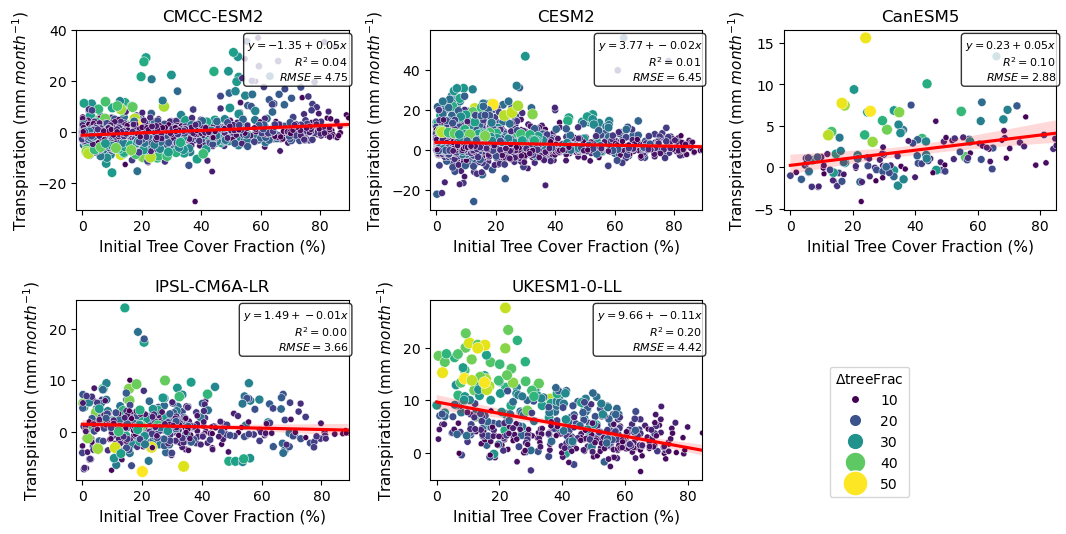

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 6

fig = plt.figure(figsize=(width_inch, height_inch))
gs = gridspec.GridSpec(2, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)

for m, mm in enumerate(models_tran):

    df = df_tran[df_tran["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    else:
        axs = fig.add_subplot(gs[1, m-3])

    axs = sns.scatterplot(data=df, x="treeFrac_ctl", y="tran", hue='treeFrac_delta', size="treeFrac_delta", size_order=[10, 20, 30, 40, 50], palette="viridis")
    axs = sns.regplot(data=df, x="treeFrac_ctl", y="tran", scatter = False, ci=99, line_kws={"color": "red"})
    X = df["treeFrac_ctl"].values.reshape(-1, 1)
    y = df["tran"].values
    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    intercept = model.intercept_
    slope = model.coef_[0]

    equation = f'$y = {intercept:.2f} + {slope:.2f}x$ \n$R^2 = {r2:.2f}$ \n$RMSE = {rmse:.2f}$'
    axs.annotate(equation, xy=(1., 0.95), xycoords='axes fraction',
                 fontsize=8, ha='right', va='top',
                 bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.8))

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("Initial Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Transpiration (mm $month^{-1}$)", fontsize = 11)
    axs.set_title(models_tran[m])

    if m == 4:
        custom_lines = [
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(10)), markersize=6),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(20)), markersize=9),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(30)), markersize=12),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(40)), markersize=15),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(50)), markersize=18),
        ]
        fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='$\Delta$treeFrac', loc='upper right', bbox_to_anchor=(0.7, 0.4), fontsize=10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_Tran_vs_initial_treeFrac"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### Tran vs $\Delta$ treeFrac (already existed in the source notebook, unchanged apart from the `v1_` filename)

<>:40: SyntaxWarning: invalid escape sequence '\D'
<>:40: SyntaxWarning: invalid escape sequence '\D'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_72004/2442721705.py:40: SyntaxWarning: invalid escape sequence '\D'
  axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)


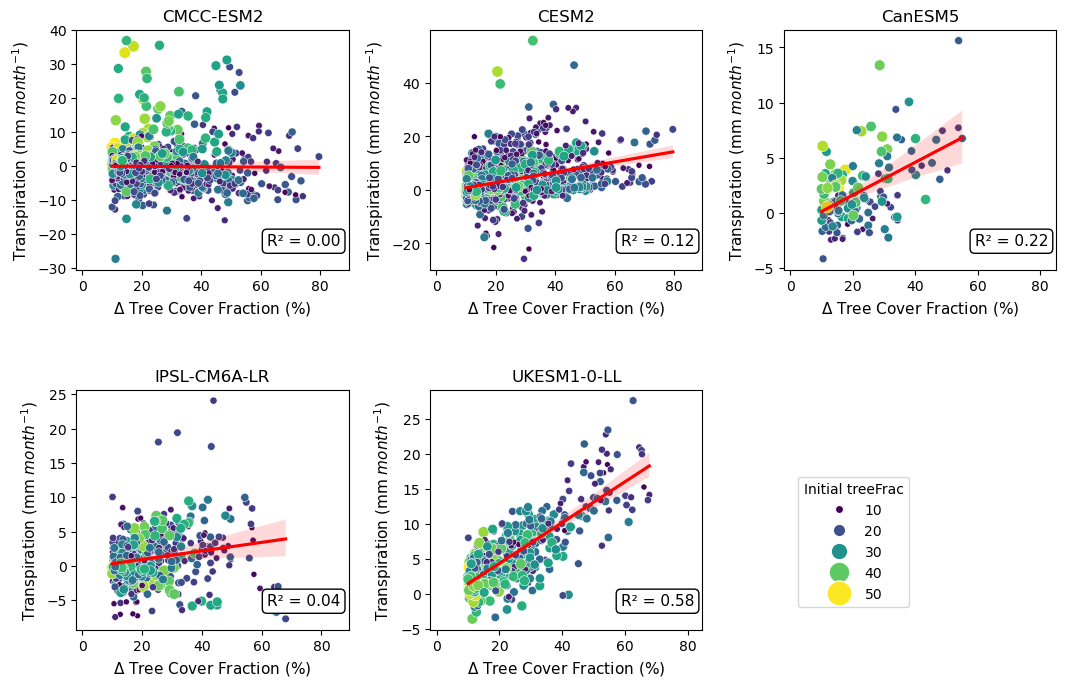

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(2, 3)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=10, vmax=50)

for m, mm in enumerate(models_tran):

    df = df_tran[df_tran["models"] == mm]
    df = df[df["treeFrac_ctl"] > 0]     #Necessary to avoid zero for logarithmic fitting
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.scatterplot(data=df, x="treeFrac_delta", y="tran", hue='treeFrac_ctl', size="treeFrac_ctl", size_order=[10, 20, 30, 40, 50], palette=cmap) #, palette=['indianred', 'lightblue'])
    axs = sns.regplot(data=df, x="treeFrac_delta", y="tran", scatter = False, ci=99, line_kws={"color": "red"})
    # Compute R\xb2 value
    X = np.log(df["treeFrac_delta"].values).reshape(-1, 1)
    y = df["tran"].values
    model = LinearRegression().fit(X, y)
    r2 = r2_score(y, model.predict(X))

    # Annotate R\xb2 value
    axs.annotate(f'R² = {r2:.2f}', xy=(0.7, 0.15), xycoords='axes fraction',
                     fontsize=11, ha='left', va='top', bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white"))

    axs.legend_.remove()
    axs.set_xlim(-2,df.treeFrac_ctl.max())
    axs.set_xlabel("$\Delta$ Tree Cover Fraction (%)", fontsize = 11)
    axs.set_ylabel("Transpiration (mm $month^{-1}$)", fontsize = 11)
    axs.set_title(models_tran[m])

    if m == 4:
        custom_lines = [
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(10)), markersize=6),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(20)), markersize=9),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(30)), markersize=12),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(40)), markersize=15),
            Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(norm(50)), markersize=18),
        ]
        fig.legend(custom_lines, ['10', '20', '30', '40', '50'], title='Initial treeFrac', loc='upper right', bbox_to_anchor=(0.7, 0.4), fontsize=10)

fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

title = "v1_Tran_vs_delta_treeFrac"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()